# Credit Card Fraud Detection — Model Training and Evaluation

This notebook develops and evaluates machine learning models for detecting fraudulent credit card transactions.

The modeling workflow focuses on:

- Leakage-safe train/test splitting
- Baseline model development
- Handling severe class imbalance
- Model evaluation using fraud-focused metrics
- Comparison of different modeling strategies
- Selection of a final candidate model

Because fraudulent transactions represent only a very small fraction of the dataset, accuracy alone is not an appropriate primary evaluation metric. Precision, recall, F1-score, ROC-AUC, and especially PR-AUC will be considered.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

RANDOM_STATE = 42

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

sns.set_theme(style="whitegrid")

## 1. Load Dataset

In [2]:
DATA_PATH = "../data/creditcard.csv"

df = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0000,-1.3598,-0.0728,2.5363,1.3782,-0.3383,0.4624,0.2396,0.0987,0.3638,0.0908,-0.5516,-0.6178,-0.9914,-0.3112,1.4682,-0.4704,0.2080,0.0258,0.4040,0.2514,-0.0183,0.2778,-0.1105,0.0669,0.1285,-0.1891,0.1336,-0.0211,149.6200,0
1,0.0000,1.1919,0.2662,0.1665,0.4482,0.0600,-0.0824,-0.0788,0.0851,-0.2554,-0.1670,1.6127,1.0652,0.4891,-0.1438,0.6356,0.4639,-0.1148,-0.1834,-0.1458,-0.0691,-0.2258,-0.6387,0.1013,-0.3398,0.1672,0.1259,-0.0090,0.0147,2.6900,0
2,1.0000,-1.3584,-1.3402,1.7732,0.3798,-0.5032,1.8005,0.7915,0.2477,-1.5147,0.2076,0.6245,0.0661,0.7173,-0.1659,2.3459,-2.8901,1.1100,-0.1214,-2.2619,0.5250,0.2480,0.7717,0.9094,-0.6893,-0.3276,-0.1391,-0.0554,-0.0598,378.6600,0
3,1.0000,-0.9663,-0.1852,1.7930,-0.8633,-0.0103,1.2472,0.2376,0.3774,-1.3870,-0.0550,-0.2265,0.1782,0.5078,-0.2879,-0.6314,-1.0596,-0.6841,1.9658,-1.2326,-0.2080,-0.1083,0.0053,-0.1903,-1.1756,0.6474,-0.2219,0.0627,0.0615,123.5000,0
4,2.0000,-1.1582,0.8777,1.5487,0.4030,-0.4072,0.0959,0.5929,-0.2705,0.8177,0.7531,-0.8228,0.5382,1.3459,-1.1197,0.1751,-0.4514,-0.2370,-0.0382,0.8035,0.4085,-0.0094,0.7983,-0.1375,0.1413,-0.2060,0.5023,0.2194,0.2152,69.9900,0


## 2. Define Features and Target

The target variable is `Class`:

- `0` = legitimate transaction
- `1` = fraudulent transaction

All remaining variables are initially considered candidate predictor features.

In [3]:
X = df.drop(columns=["Class"])
y = df["Class"]

print(f"Feature matrix shape: {X.shape}")
print(f"Target shape: {y.shape}")
print(f"Fraudulent transactions: {(y == 1).sum():,}")
print(f"Legitimate transactions: {(y == 0).sum():,}")

Feature matrix shape: (284807, 30)
Target shape: (284807,)
Fraudulent transactions: 492
Legitimate transactions: 284,315


## 3. Train/Test Split

The dataset is divided into training and testing sets before any resampling or model fitting.

Stratification is used to preserve the very small proportion of fraudulent transactions in both subsets.

The test set will remain untouched during model development and will only be used for final evaluation.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print(f"Training samples: {len(X_train):,}")
print(f"Testing samples: {len(X_test):,}")

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 227,845
Testing samples: 56,962

Training class distribution:
Class
0    227451
1       394
Name: count, dtype: int64

Testing class distribution:
Class
0    56864
1       98
Name: count, dtype: int64


## 4. Feature Preprocessing

Logistic Regression is sensitive to feature scale because it estimates model coefficients based on the numerical values of the input features.

The `Amount` and `Time` variables have different scales from the anonymized `V1`–`V28` features. Therefore, feature standardization will be applied.

The scaler will be fitted only on the training data and then used to transform both the training and testing sets. This prevents information from the test set from leaking into the preprocessing stage.

In [5]:
X_train.describe().T[["mean", "std", "min", "max"]].head(10)

,mean,std,min,max
Time,94885.0937,47488.4150,0.0000,172792.0000
V1,0.0008,1.9589,-56.4075,2.4519
V2,-0.0005,1.6491,-72.7157,22.0577
V3,-0.0004,1.5153,-48.3256,9.3826
V4,-0.0000,1.4159,-5.6832,16.8753
V5,0.0002,1.3796,-113.7433,34.8017
V6,-0.0012,1.3312,-26.1605,73.3016
V7,0.0001,1.2384,-43.5572,120.5895
V8,-0.0004,1.1915,-73.2167,20.0072
V9,0.0007,1.0974,-13.4341,15.5950


In [6]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Scaled training data shape: {X_train_scaled.shape}")
print(f"Scaled testing data shape: {X_test_scaled.shape}")

Scaled training data shape: (227845, 30)
Scaled testing data shape: (56962, 30)


## 5. Baseline Logistic Regression

Logistic Regression is used as the first baseline classification model.

The initial model does not use SMOTE or class weighting. This provides a reference point for evaluating whether later imbalance-handling techniques actually improve fraud detection performance.

In [7]:
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

logistic_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


## 6. Baseline Model Predictions

In [8]:
y_pred = logistic_model.predict(X_test_scaled)
y_pred_proba = logistic_model.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


## 7. Baseline Model Evaluation

Because the dataset is highly imbalanced, accuracy is not sufficient for evaluating fraud detection performance.

We therefore examine:

- Precision
- Recall
- F1-score
- ROC-AUC
- PR-AUC
- Confusion Matrix

In [9]:
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_pred_proba)
pr_auc = average_precision_score(y_test, y_pred_proba)

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")
print(f"PR-AUC:    {pr_auc:.4f}")

Precision: 0.8267
Recall:    0.6327
F1-score:  0.7168
ROC-AUC:   0.9605
PR-AUC:    0.7414


## 8. Classification Report

In [10]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Legitimate", "Fraudulent"]
))

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
  Fraudulent       0.83      0.63      0.72        98

    accuracy                           1.00     56962
   macro avg       0.91      0.82      0.86     56962
weighted avg       1.00      1.00      1.00     56962



## 9. Confusion Matrix

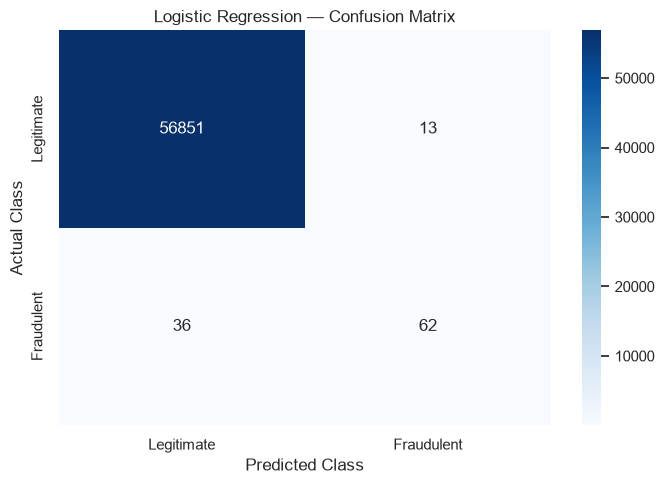

In [11]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraudulent"],
    yticklabels=["Legitimate", "Fraudulent"]
)

plt.title("Logistic Regression — Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

## 10. Class-Weighted Logistic Regression

The baseline model treats legitimate and fraudulent transactions equally during training.

Because fraudulent transactions are extremely rare, we now train a second Logistic Regression model using `class_weight="balanced"`.

This automatically assigns greater importance to the minority fraud class during model training.

In [12]:
balanced_logistic_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

balanced_logistic_model.fit(X_train_scaled, y_train)

print("Class-weighted Logistic Regression model trained successfully.")

Class-weighted Logistic Regression model trained successfully.


In [13]:
balanced_y_pred = balanced_logistic_model.predict(X_test_scaled)
balanced_y_pred_proba = balanced_logistic_model.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


In [14]:
balanced_precision = precision_score(y_test, balanced_y_pred)
balanced_recall = recall_score(y_test, balanced_y_pred)
balanced_f1 = f1_score(y_test, balanced_y_pred)
balanced_roc_auc = roc_auc_score(y_test, balanced_y_pred_proba)
balanced_pr_auc = average_precision_score(y_test, balanced_y_pred_proba)

print(f"Precision: {balanced_precision:.4f}")
print(f"Recall:    {balanced_recall:.4f}")
print(f"F1-score:  {balanced_f1:.4f}")
print(f"ROC-AUC:   {balanced_roc_auc:.4f}")
print(f"PR-AUC:    {balanced_pr_auc:.4f}")

Precision: 0.0610
Recall:    0.9184
F1-score:  0.1144
ROC-AUC:   0.9721
PR-AUC:    0.7190


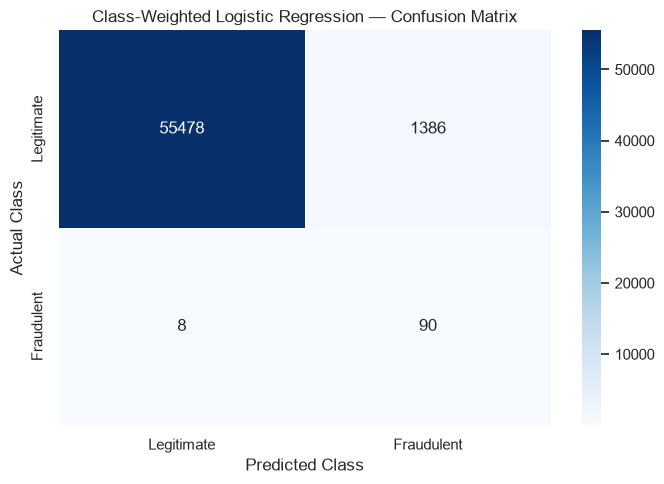

In [15]:
balanced_cm = confusion_matrix(y_test, balanced_y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    balanced_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraudulent"],
    yticklabels=["Legitimate", "Fraudulent"]
)

plt.title("Class-Weighted Logistic Regression — Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()

## 11. Baseline vs Class-Weighted Logistic Regression

The baseline Logistic Regression model achieved higher precision, while the class-weighted model achieved substantially higher recall.

The baseline model detected 62 of the 98 fraudulent transactions in the test set, while the class-weighted model detected 90 of 98.

However, the class-weighted model also produced substantially more false positives, increasing from 13 to 1,386.

This demonstrates the precision-recall trade-off associated with handling severe class imbalance.

### Performance Comparison

In [16]:
comparison_results = pd.DataFrame({
    "Model": [
        "Baseline Logistic Regression",
        "Class-Weighted Logistic Regression"
    ],
    "Precision": [
        precision,
        balanced_precision
    ],
    "Recall": [
        recall,
        balanced_recall
    ],
    "F1-Score": [
        f1,
        balanced_f1
    ],
    "ROC-AUC": [
        roc_auc,
        balanced_roc_auc
    ],
    "PR-AUC": [
        pr_auc,
        balanced_pr_auc
    ]
})

comparison_results

,Model,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Baseline Logistic Regression,0.8267,0.6327,0.7168,0.9605,0.7414
1,Class-Weighted Logistic Regression,0.0610,0.9184,0.1144,0.9721,0.7190


## 12. Classification Threshold Analysis

The default classification threshold of 0.50 is not necessarily optimal for fraud detection.

Because changing the threshold changes the balance between false positives and false negatives, we will evaluate multiple probability thresholds and examine their effect on precision, recall, and F1-score.

This analysis will help us understand the operating characteristics of the Logistic Regression model before moving to more advanced modeling approaches.

In [17]:
thresholds = np.arange(0.10, 0.91, 0.05)

threshold_results = []

for threshold in thresholds:
    threshold_pred = (y_pred_proba >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, threshold_pred, zero_division=0),
        "Recall": recall_score(y_test, threshold_pred, zero_division=0),
        "F1-Score": f1_score(y_test, threshold_pred, zero_division=0)
    })

threshold_results = pd.DataFrame(threshold_results)

threshold_results

,Threshold,Precision,Recall,F1-Score
0,0.1000,0.7009,0.7653,0.7317
1,0.1500,0.7282,0.7653,0.7463
2,0.2000,0.7347,0.7347,0.7347
3,0.2500,0.7292,0.7143,0.7216
4,0.3000,0.7312,0.6939,0.7120
5,0.3500,0.7416,0.6735,0.7059
6,0.4000,0.7529,0.6531,0.6995
7,0.4500,0.8077,0.6429,0.7159
8,0.5000,0.8267,0.6327,0.7168
9,0.5500,0.8267,0.6327,0.7168


## 13. Validation Set for Model Selection

The original training data is further divided into training and validation subsets.

The validation set will be used for model selection, threshold analysis, and other development decisions.

The test set remains untouched until final evaluation.

In [18]:
X_train_model, X_val, y_train_model, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=RANDOM_STATE
)

print(f"Model-training samples: {len(X_train_model):,}")
print(f"Validation samples:     {len(X_val):,}")
print(f"Test samples:           {len(X_test):,}")

print("\nModel-training class distribution:")
print(y_train_model.value_counts())

print("\nValidation class distribution:")
print(y_val.value_counts())

print("\nTest class distribution:")
print(y_test.value_counts())

Model-training samples: 182,276
Validation samples:     45,569
Test samples:           56,962

Model-training class distribution:
Class
0    181961
1       315
Name: count, dtype: int64

Validation class distribution:
Class
0    45490
1       79
Name: count, dtype: int64

Test class distribution:
Class
0    56864
1       98
Name: count, dtype: int64


## 14. Leakage-Safe Feature Scaling

A new scaler is fitted only on the model-training data.

The same transformation is then applied to the validation and test sets without refitting the scaler.

In [19]:
model_scaler = StandardScaler()

X_train_model_scaled = model_scaler.fit_transform(X_train_model)
X_val_scaled = model_scaler.transform(X_val)
X_test_scaled = model_scaler.transform(X_test)

print("Training shape:", X_train_model_scaled.shape)
print("Validation shape:", X_val_scaled.shape)
print("Test shape:", X_test_scaled.shape)

Training shape: (182276, 30)
Validation shape: (45569, 30)
Test shape: (56962, 30)


## 15. Baseline Logistic Regression — Validation Evaluation

A baseline Logistic Regression model is trained on the model-training set.

Its performance is evaluated on the validation set using the default classification threshold of 0.50.

In [20]:
baseline_model = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

baseline_model.fit(
    X_train_model_scaled,
    y_train_model
)

val_pred = baseline_model.predict(X_val_scaled)
val_pred_proba = baseline_model.predict_proba(X_val_scaled)[:, 1]

print("Validation Results — Baseline Logistic Regression")
print("-" * 50)

print(f"Precision: {precision_score(y_val, val_pred):.4f}")
print(f"Recall:    {recall_score(y_val, val_pred):.4f}")
print(f"F1-Score:  {f1_score(y_val, val_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_val, val_pred_proba):.4f}")
print(f"PR-AUC:    {average_precision_score(y_val, val_pred_proba):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, val_pred))

Validation Results — Baseline Logistic Regression
--------------------------------------------------
Precision: 0.8333
Recall:    0.5063
F1-Score:  0.6299
ROC-AUC:   0.9643
PR-AUC:    0.7088

Confusion Matrix:
[[45482     8]
 [   39    40]]


## 16. Class-Weighted Logistic Regression

Class weighting gives greater importance to fraudulent transactions during model training.

This experiment evaluates whether increasing the cost of misclassifying fraud improves recall.

In [21]:
balanced_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=RANDOM_STATE
)

balanced_model.fit(
    X_train_model_scaled,
    y_train_model
)

balanced_val_pred = balanced_model.predict(X_val_scaled)
balanced_val_pred_proba = balanced_model.predict_proba(X_val_scaled)[:, 1]

print("Validation Results — Class-Weighted Logistic Regression")
print("-" * 55)

print(f"Precision: {precision_score(y_val, balanced_val_pred):.4f}")
print(f"Recall:    {recall_score(y_val, balanced_val_pred):.4f}")
print(f"F1-Score:  {f1_score(y_val, balanced_val_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_val, balanced_val_pred_proba):.4f}")
print(f"PR-AUC:    {average_precision_score(y_val, balanced_val_pred_proba):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, balanced_val_pred))

Validation Results — Class-Weighted Logistic Regression
-------------------------------------------------------
Precision: 0.0599
Recall:    0.8861
F1-Score:  0.1123
ROC-AUC:   0.9736
PR-AUC:    0.6790

Confusion Matrix:
[[44392  1098]
 [    9    70]]


## 17. Validation Model Comparison

The baseline and class-weighted Logistic Regression models are compared using the validation set.

This comparison helps determine how class weighting changes the precision-recall tradeoff.

In [22]:
validation_comparison = pd.DataFrame({
    "Model": [
        "Baseline Logistic Regression",
        "Class-Weighted Logistic Regression"
    ],
    "Precision": [
        precision_score(y_val, val_pred),
        precision_score(y_val, balanced_val_pred)
    ],
    "Recall": [
        recall_score(y_val, val_pred),
        recall_score(y_val, balanced_val_pred)
    ],
    "F1-Score": [
        f1_score(y_val, val_pred),
        f1_score(y_val, balanced_val_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_val, val_pred_proba),
        roc_auc_score(y_val, balanced_val_pred_proba)
    ],
    "PR-AUC": [
        average_precision_score(y_val, val_pred_proba),
        average_precision_score(y_val, balanced_val_pred_proba)
    ]
})

validation_comparison

,Model,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Baseline Logistic Regression,0.8333,0.5063,0.6299,0.9643,0.7088
1,Class-Weighted Logistic Regression,0.0599,0.8861,0.1123,0.9736,0.6790


## 18. Validation-Based Threshold Analysis

The baseline Logistic Regression model's probability threshold is varied using
the validation set.

This allows us to examine the precision-recall tradeoff and identify a
candidate threshold without using the final test set.

In [23]:
thresholds = np.arange(0.05, 0.96, 0.05)

validation_threshold_results = []

for threshold in thresholds:
    threshold_pred = (val_pred_proba >= threshold).astype(int)

    validation_threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_val, threshold_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, threshold_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_val, threshold_pred, zero_division=0
        )
    })

validation_threshold_results = pd.DataFrame(
    validation_threshold_results
)

validation_threshold_results

,Threshold,Precision,Recall,F1-Score
0,0.0500,0.7308,0.7215,0.7261
1,0.1000,0.7971,0.6962,0.7432
2,0.1500,0.7969,0.6456,0.7133
3,0.2000,0.8065,0.6329,0.7092
4,0.2500,0.8033,0.6203,0.7000
5,0.3000,0.8214,0.5823,0.6815
6,0.3500,0.8113,0.5443,0.6515
7,0.4000,0.8039,0.5190,0.6308
8,0.4500,0.8000,0.5063,0.6202
9,0.5000,0.8333,0.5063,0.6299


## 19. Fine-Grained Threshold Analysis

The initial threshold analysis identified a promising region around 0.10.

A finer threshold grid is evaluated on the validation set to better understand
the precision-recall tradeoff before selecting a candidate operating threshold.

In [24]:
fine_thresholds = np.arange(0.05, 0.201, 0.01)

fine_threshold_results = []

for threshold in fine_thresholds:
    threshold_pred = (val_pred_proba >= threshold).astype(int)

    fine_threshold_results.append({
        "Threshold": round(threshold, 2),
        "Precision": precision_score(
            y_val, threshold_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_val, threshold_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_val, threshold_pred, zero_division=0
        )
    })

fine_threshold_results = pd.DataFrame(fine_threshold_results)

fine_threshold_results

,Threshold,Precision,Recall,F1-Score
0,0.0500,0.7308,0.7215,0.7261
1,0.0600,0.7857,0.6962,0.7383
2,0.0700,0.7971,0.6962,0.7432
3,0.0800,0.7971,0.6962,0.7432
4,0.0900,0.7971,0.6962,0.7432
5,0.1000,0.7971,0.6962,0.7432
6,0.1100,0.7910,0.6709,0.7260
7,0.1200,0.7969,0.6456,0.7133
8,0.1300,0.7969,0.6456,0.7133
9,0.1400,0.7969,0.6456,0.7133


## 20. Precision-Recall Tradeoff

The precision and recall of the baseline Logistic Regression model are
visualized across different decision thresholds.

This illustrates how changing the classification threshold affects fraud
detection performance.

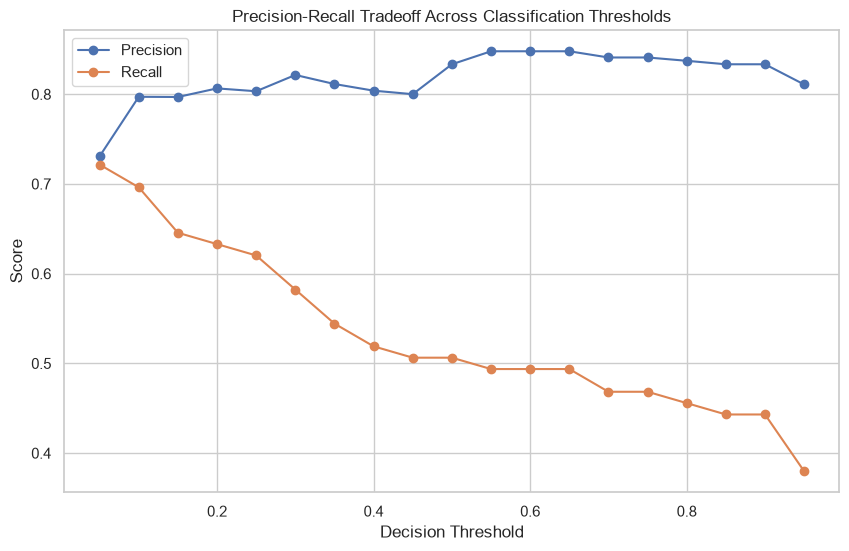

In [25]:
plt.figure(figsize=(10, 6))

plt.plot(
    validation_threshold_results["Threshold"],
    validation_threshold_results["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    validation_threshold_results["Threshold"],
    validation_threshold_results["Recall"],
    marker="o",
    label="Recall"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Precision-Recall Tradeoff Across Classification Thresholds")
plt.legend()
plt.grid(True)

plt.show()

## 21. SMOTE + Logistic Regression

SMOTE is used to synthetically oversample the minority fraud class in the
model-training data.

SMOTE is applied only during model training. The validation and test sets
retain their original class distributions.

In [26]:
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

smote_logistic_model = ImbPipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

smote_logistic_model.fit(
    X_train_model,
    y_train_model
)

smote_val_pred = smote_logistic_model.predict(X_val)
smote_val_pred_proba = smote_logistic_model.predict_proba(X_val)[:, 1]

print("Validation Results — SMOTE Logistic Regression")
print("-" * 50)

print(f"Precision: {precision_score(y_val, smote_val_pred):.4f}")
print(f"Recall:    {recall_score(y_val, smote_val_pred):.4f}")
print(f"F1-Score:  {f1_score(y_val, smote_val_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_val, smote_val_pred_proba):.4f}")
print(f"PR-AUC:    {average_precision_score(y_val, smote_val_pred_proba):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, smote_val_pred))

Validation Results — SMOTE Logistic Regression
--------------------------------------------------
Precision: 0.0542
Recall:    0.8734
F1-Score:  0.1021
ROC-AUC:   0.9687
PR-AUC:    0.6814

Confusion Matrix:
[[44286  1204]
 [   10    69]]


In [27]:
final_validation_comparison = pd.DataFrame({
    "Model": [
        "Baseline Logistic Regression",
        "Class-Weighted Logistic Regression",
        "SMOTE Logistic Regression"
    ],
    "Precision": [
        precision_score(y_val, val_pred),
        precision_score(y_val, balanced_val_pred),
        precision_score(y_val, smote_val_pred)
    ],
    "Recall": [
        recall_score(y_val, val_pred),
        recall_score(y_val, balanced_val_pred),
        recall_score(y_val, smote_val_pred)
    ],
    "F1-Score": [
        f1_score(y_val, val_pred),
        f1_score(y_val, balanced_val_pred),
        f1_score(y_val, smote_val_pred)
    ],
    "ROC-AUC": [
        roc_auc_score(y_val, val_pred_proba),
        roc_auc_score(y_val, balanced_val_pred_proba),
        roc_auc_score(y_val, smote_val_pred_proba)
    ],
    "PR-AUC": [
        average_precision_score(y_val, val_pred_proba),
        average_precision_score(y_val, balanced_val_pred_proba),
        average_precision_score(y_val, smote_val_pred_proba)
    ]
})

final_validation_comparison

,Model,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Baseline Logistic Regression,0.8333,0.5063,0.6299,0.9643,0.7088
1,Class-Weighted Logistic Regression,0.0599,0.8861,0.1123,0.9736,0.6790
2,SMOTE Logistic Regression,0.0542,0.8734,0.1021,0.9687,0.6814


## 22. Final Evaluation on the Test Set

The model and decision threshold were selected using the training and validation
data only.

The test set is now evaluated once as an unbiased estimate of final performance.

In [28]:
FINAL_THRESHOLD = 0.10

test_proba = baseline_model.predict_proba(X_test_scaled)[:, 1]

test_pred = (test_proba >= FINAL_THRESHOLD).astype(int)

print("Final Test Results")
print("-" * 40)

print(f"Threshold: {FINAL_THRESHOLD:.2f}")
print(f"Precision: {precision_score(y_test, test_pred):.4f}")
print(f"Recall:    {recall_score(y_test, test_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, test_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, test_proba):.4f}")
print(f"PR-AUC:    {average_precision_score(y_test, test_proba):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_pred))

print("\nClassification Report:")
print(classification_report(y_test, test_pred, digits=4))

Final Test Results
----------------------------------------
Threshold: 0.10
Precision: 0.7115
Recall:    0.7551
F1-Score:  0.7327
ROC-AUC:   0.9537
PR-AUC:    0.7377

Confusion Matrix:
[[56834    30]
 [   24    74]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9996    0.9995    0.9995     56864
           1     0.7115    0.7551    0.7327        98

    accuracy                         0.9991     56962
   macro avg     0.8556    0.8773    0.8661     56962
weighted avg     0.9991    0.9991    0.9991     56962



## 23. Save Final Model

The final Logistic Regression model, feature scaler, and selected decision
threshold are saved for later inference and deployment.

In [29]:
import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(baseline_model, MODEL_DIR / "logistic_regression_model.joblib")
joblib.dump(model_scaler, MODEL_DIR / "feature_scaler.joblib")

joblib.dump(
    {"threshold": FINAL_THRESHOLD},
    MODEL_DIR / "decision_threshold.joblib"
)

print("Final model artifacts saved:")
print("- logistic_regression_model.joblib")
print("- feature_scaler.joblib")
print("- decision_threshold.joblib")

Final model artifacts saved:
- logistic_regression_model.joblib
- feature_scaler.joblib
- decision_threshold.joblib


<Figure size 800x600 with 0 Axes>

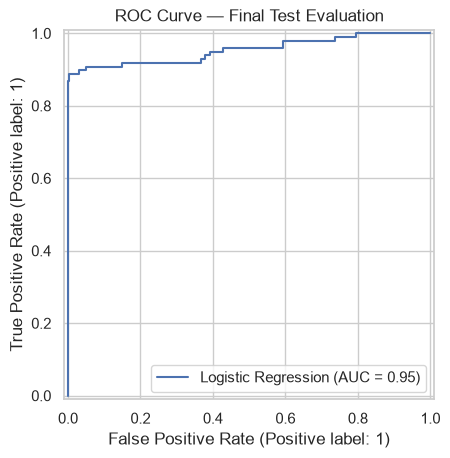

<Figure size 800x600 with 0 Axes>

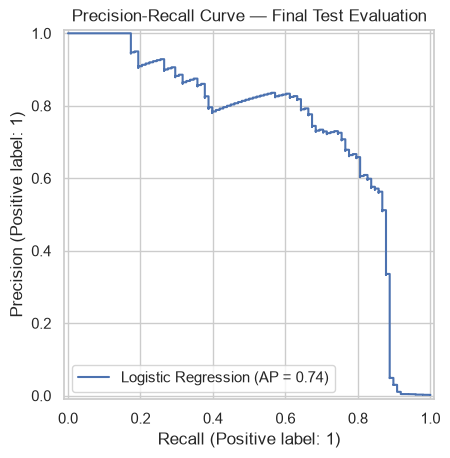

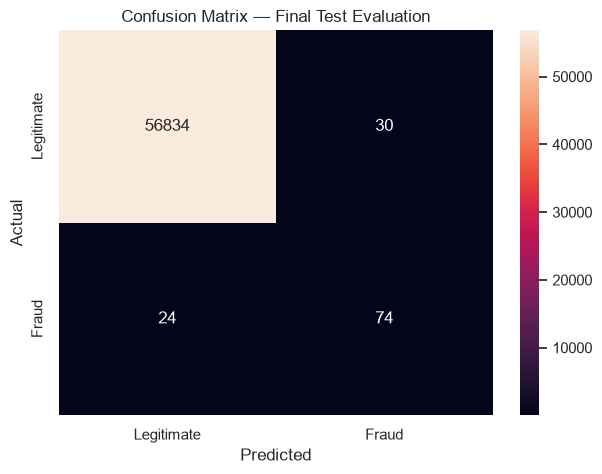

In [30]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay

FIGURE_DIR = Path("../reports/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# ROC Curve
plt.figure(figsize=(8, 6))
RocCurveDisplay.from_predictions(
    y_test,
    test_proba,
    name="Logistic Regression"
)
plt.title("ROC Curve — Final Test Evaluation")
plt.grid(True)
plt.savefig(
    FIGURE_DIR / "final_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# Precision-Recall Curve
plt.figure(figsize=(8, 6))
PrecisionRecallDisplay.from_predictions(
    y_test,
    test_proba,
    name="Logistic Regression"
)
plt.title("Precision-Recall Curve — Final Test Evaluation")
plt.grid(True)
plt.savefig(
    FIGURE_DIR / "final_precision_recall_curve.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# Confusion Matrix
cm = confusion_matrix(y_test, test_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix — Final Test Evaluation")
plt.savefig(
    FIGURE_DIR / "final_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [31]:
final_metrics = pd.DataFrame({
    "Metric": [
        "Threshold",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC",
        "PR-AUC",
        "True Negatives",
        "False Positives",
        "False Negatives",
        "True Positives"
    ],
    "Value": [
        FINAL_THRESHOLD,
        precision_score(y_test, test_pred),
        recall_score(y_test, test_pred),
        f1_score(y_test, test_pred),
        roc_auc_score(y_test, test_proba),
        average_precision_score(y_test, test_proba),
        cm[0, 0],
        cm[0, 1],
        cm[1, 0],
        cm[1, 1]
    ]
})

final_metrics.to_csv(
    "../reports/final_metrics.csv",
    index=False
)

final_metrics

,Metric,Value
0,Threshold,0.1000
1,Precision,0.7115
2,Recall,0.7551
3,F1-Score,0.7327
4,ROC-AUC,0.9537
5,PR-AUC,0.7377
6,True Negatives,56834.0000
7,False Positives,30.0000
8,False Negatives,24.0000
9,True Positives,74.0000
